# 01 — Préparation du nouvel historique Sentinel-2

Source unique : historique vérifié 2021–2025, 563 polygones éligibles. Prévision du NDVI du mois suivant, six mois d’entrée. Ce notebook remplace l’ancien pilote et ne télécharge rien.

## 1. Préparer les chemins et les bibliothèques

**But :** Définir les entrées du nouveau dataset et le dossier de sortie.

**Méthode et justification :** Le notebook part de la racine du projet et ne lance aucun téléchargement. Les anciennes données ne sont pas utilisées.

**Résultat attendu :** Les chemins ROOT, DATA et PREP sont disponibles.

In [1]:
from pathlib import Path
import json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT=Path.cwd()
assert (ROOT/'data').exists(), 'Ouvrir le notebook depuis la racine SmartOlive_Sate.'
DATA=ROOT/'data/processed/sentinel_history_2021_2025'
PREP=ROOT/'data/processed/model_inputs_sentinel'
PREP.mkdir(parents=True,exist_ok=True)

## 2. Vérifier la fin de l’import et l’intégrité

**But :** S’assurer que le fichier analysé est celui qui a été validé.

**Méthode et justification :** Le statut doit indiquer un import terminé sans erreur active. L’empreinte SHA-256 du CSV est comparée au manifeste : une différence demande de refaire la vérification de l’import.

**Résultat attendu :** Les assertions passent ; sinon, arrêter la préparation et rechercher la cause.

In [2]:
status=json.loads((DATA/'status.json').read_text(encoding='utf-8'))
assert status['complete'] and status['errors']==0
verification=json.loads((ROOT/'outputs/sentinel_history_2021_2025/verification.json').read_text(encoding='utf-8'))
source_hash=hashlib.sha256((DATA/'monthly_history.csv').read_bytes()).hexdigest()
assert source_hash==verification['calendar_sha256']

## 3. Charger, contrôler et décrire les observations

**But :** Lire les mesures et distinguer données valides et mois manquants.

**Méthode et justification :** Les dates ISO acceptent des fractions de seconde facultatives. Les couples parcelle–mois doivent être uniques. Une observation rejetée ne doit pas avoir de réflectance ou indice exploitable ; le NDVI accepté doit rester entre −1 et 1. Le tableau compte les mesures valides par année. Le nettoyage radiométrique et nuageux a déjà été effectué à l’import : SCL 4/5, au moins 60 % de pixels valides et neuf pixels par polygone. Aucune interpolation n’est ajoutée ici.

**Résultat attendu :** Une grille de 60 mois avec des trous explicites, particulièrement nombreux en 2022.

In [3]:
data=pd.read_csv(DATA/'monthly_history.csv')
data['time']=pd.to_datetime(data.month)
data['acquisition_date']=pd.to_datetime(data.acquisition_date,utc=True,format='ISO8601')
assert not data.duplicated(['parcel_id','month']).any()
assert data.loc[~data.accepted,['ndvi','savi','red','nir']].isna().all().all()
assert data.loc[data.accepted,'ndvi'].between(-1,1).all()
display(data.groupby(data.time.dt.year).accepted.agg(['sum','size']))

,sum,size
time,,
2021,6726,6756
2022,758,6756
2023,6720,6756
2024,6728,6756
2025,6725,6756


## 4. Réserver les groupes spatiaux

**But :** Tester la généralisation sur des parcelles absentes de l’apprentissage.

**Méthode et justification :** Les polygones fortement superposés partagent un groupe. Environ 20 % des groupes de chaque région sont réservés avec un classement SHA-256 reproductible. Aucun de leurs exemples ne passe dans le train ou la validation. Un groupe spatial ne correspond pas forcément à une exploitation indépendante.

**Résultat attendu :** Un ensemble holdout de groupes destiné au test spatial final.

In [4]:
# Réserver environ 20 % des groupes spatiaux dans chaque région.
# Les parcelles fortement superposées restent toujours dans le même groupe.
groups=pd.read_csv(ROOT/'outputs/sentinel_history_2021_2025/spatial_groups.csv')
data=data.merge(groups,on='parcel_id',validate='many_to_one')
holdout=set()
for region,part in data.groupby('region'):
    units=sorted(part.spatial_group.unique(),key=lambda s:hashlib.sha256(s.encode()).hexdigest())
    holdout.update(units[:max(1,round(.2*len(units)))])

## 5. Définir les caractéristiques et la chronologie

**But :** Préparer les variables d’entrée et les frontières train/validation/test.

**Méthode et justification :** Entrées : NDVI, SAVI, rouge, proche infrarouge et mois encodé en sinus/cosinus. Ce codage rapproche décembre et janvier. Les identifiants ne sont pas des prédicteurs. Les 60 mois sont divisés en 42/9/9 : train janvier 2021–juin 2024 ; validation juillet 2024–mars 2025 ; test avril–décembre 2025. Les indices/réflectances sont partiellement redondants : leur présence ne constitue pas une preuve d’apport indépendant.

**Résultat attendu :** La liste des caractéristiques et les frontières temporelles sont fixées.

In [5]:
data['NDVI']=data.ndvi
data['month_sin']=np.sin(2*np.pi*data.time.dt.month/12)
data['month_cos']=np.cos(2*np.pi*data.time.dt.month/12)
features=['NDVI','savi','red','nir','month_sin','month_cos']
months=sorted(data.month.unique())
assert len(months)==60
a,b=int(.7*len(months)),int(.85*len(months))

## 6. Construire les séquences de prévision

**But :** Apprendre à prévoir le NDVI du mois suivant à partir de six mois passés.

**Méthode et justification :** Chaque exemple contient six observations mensuelles en entrée et un NDVI cible au septième mois. Les sept mois doivent être valides et rester dans le même bloc ; une fenêtre incomplète est exclue, sans remplissage. Le test spatial utilise uniquement les dates du bloc test. Les dates exactes sont conservées : le mois suivant n’implique pas un horizon fixe de 30 jours.

**Résultat attendu :** Quatre collections : train, validation, test temporel et test spatial indépendant du train.

In [6]:
records=[]; X={s:[] for s in ['train','validation','test','independent']}; y={s:[] for s in X}
for pid,part in data.groupby('parcel_id'):
    part=part.sort_values('time').reset_index(drop=True)
    external=part.spatial_group.iloc[0] in holdout
    for split,start,stop in [('train',0,a),('validation',a,b),('test',b,len(months))]:
        if external and split!='test':continue
        block=part.iloc[start:stop].reset_index(drop=True)
        for i in range(6,len(block)):
            window=block.iloc[i-6:i]; target=block.iloc[i]
            if not block.iloc[i-6:i+1].accepted.all():continue
            values=window[features].to_numpy(dtype=np.float32)
            if not np.isfinite(values).all():continue
            actual='independent' if external else split
            X[actual].append(values);y[actual].append(target.ndvi)
            records.append(dict(unit=pid,region=target.region,spatial_group=target.spatial_group,
                split=actual,input_start=str(window.time.iloc[0]),input_end=str(window.time.iloc[-1]),
                target_time=str(target.time),target_acquisition=str(target.acquisition_date),
                last_input_acquisition=str(window.acquisition_date.iloc[-1])))

## 7. Contrôler les fuites et former les tableaux

**But :** Garantir que l’apprentissage n’accède pas au futur ou aux groupes réservés.

**Méthode et justification :** Les tableaux X ont la forme (nombre d’exemples, 6 mois, nombre de caractéristiques). Les y sont les NDVI cibles. Les assertions vérifient les effectifs, la chronologie et la séparation des groupes ; la dernière acquisition d’entrée doit précéder l’acquisition cible. Les fenêtres glissantes restent corrélées.

**Résultat attendu :** Des tableaux numériques et des métadonnées cohérents ; les ratios finaux d’exemples peuvent différer de 70/15/15 après filtrage.

In [7]:
arrays={}
for split in X:
    assert len(X[split])>1, split
    arrays['X_'+split]=np.asarray(X[split],dtype=np.float32)
    arrays['y_'+split]=np.asarray(y[split],dtype=np.float32)
metadata=pd.DataFrame(records)
for left,right in [('train','validation'),('validation','test')]:
    assert metadata.loc[metadata.split.eq(left),'target_time'].max()<metadata.loc[metadata.split.eq(right),'input_start'].min()
assert set(metadata.loc[metadata.split.eq('independent'),'spatial_group']).isdisjoint(metadata.loc[~metadata.split.eq('independent'),'spatial_group'])
assert pd.to_datetime(metadata.last_input_acquisition,utc=True,format='ISO8601').lt(pd.to_datetime(metadata.target_acquisition,utc=True,format='ISO8601')).all()

## 8. Exporter le contrat vers le notebook 02

**But :** Rendre la préparation réutilisable dans un kernel neuf.

**Méthode et justification :** samples.npz contient X/y bruts ; samples.csv contient unités, groupes, splits et dates. Les manifestes décrivent les variables, limites, effectifs et empreintes des fichiers. La standardisation sera ajustée dans 02 sur le train uniquement, jamais sur la validation ou les tests.

**Résultat attendu :** Les fichiers sont écrits dans data/processed/model_inputs_sentinel/. Le tableau final donne les effectifs réellement retenus.

In [8]:
task=PREP/'sentinel_ndvi';task.mkdir(exist_ok=True)
np.savez_compressed(task/'samples.npz',**arrays)
metadata.to_csv(task/'samples.csv',index=False)
manifest=dict(name='sentinel_ndvi',kind='regression',description='NDVI du mois suivant à partir de six mois observés consécutifs; horizon réel variable selon les acquisitions.',
    features=features,counts=metadata.groupby('split').size().to_dict(),
    units=metadata.groupby('split').unit.nunique().to_dict(),
    provenance=['https://doi.org/10.6084/m9.figshare.28486022.v2'],source_csv_sha256=source_hash,
    limitations=['2022 très lacunaire; aucune interpolation.',
        'Culture documentée à la visite seulement; continuité 2021–2025 non confirmée.',
        'Aucun label de stress: tâche de régression, classification non évaluable.',
        'Parcelles superposées regroupées; exploitations/bassins inconnus. Les exemples restent corrélés.',
        '70/15/15 des 60 mois avant filtrage et holdout spatial; proportions finales des exemples différentes.',
        'Train janvier 2021–juin 2024; validation juillet 2024–mars 2025; test avril–décembre 2025.',
        'Groupes spatiaux réservés absents du train/validation; évaluation sur les dates du test seulement.'],
    files_sha256={f:hashlib.sha256((task/f).read_bytes()).hexdigest() for f in ['samples.npz','samples.csv']})
(task/'manifest.json').write_text(json.dumps(manifest,indent=2,ensure_ascii=False),encoding='utf-8')
(PREP/'suite_manifest.json').write_text(json.dumps([manifest],indent=2,ensure_ascii=False),encoding='utf-8')
display(metadata.groupby('split').agg(fenetres=('unit','size'),parcelles=('unit','nunique')))
print('Préparation terminée. Normalisation ajustée exclusivement sur train dans le notebook 02.')

,fenetres,parcelles
split,,
independent,338,113
test,1340,447
train,8507,448
validation,1341,447


Préparation terminée. Normalisation ajustée exclusivement sur train dans le notebook 02.


## 9. Visualiser la couverture

**But :** Repérer les périodes à faible disponibilité.

**Méthode et justification :** La fraction de parcelles acceptées est tracée chaque mois. Une chute indique une perte de données exploitables, pas nécessairement une sécheresse. Ce graphique décrit la couverture, pas la santé des oliviers.

**Résultat attendu :** Une courbe montrant notamment les lacunes de 2022.

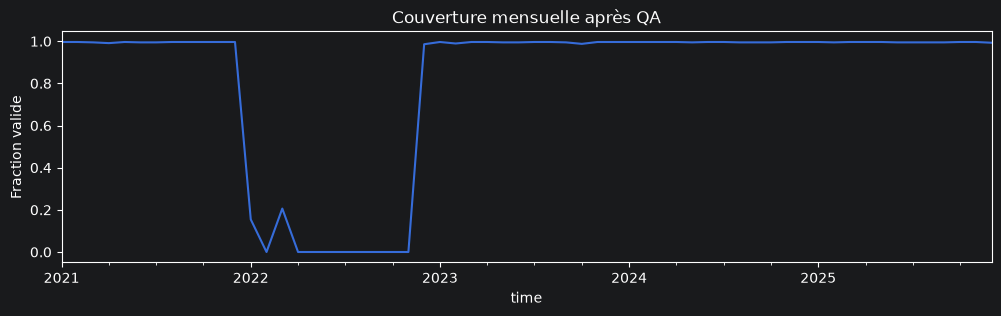

In [9]:
data.groupby('time').accepted.mean().plot(figsize=(12,3),title='Couverture mensuelle après QA',ylabel='Fraction valide'); plt.show()

### Passage au notebook 02

Une fois toutes les cellules exécutées sans erreur, ouvrir 02 dans un kernel neuf. Si les sources ou paramètres de préparation changent, réexécuter 01 avant toute nouvelle expérience.